In [ ]:
# Install dependencies
!pip install -q kaggle albumentations

# Upload kaggle.json
from google.colab import files
files.upload()

# Set credentials
import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

# Download and unzip CryoNuSeg
!kaggle datasets download -d ipateam/segmentation-of-nuclei-in-cryosectioned-he-images -p data --unzip


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/ipateam/segmentation-of-nuclei-in-cryosectioned-he-images
License(s): CC-BY-NC-SA-4.0
 76% 125M/165M [00:00<00:00, 1.30GB/s]
100% 165M/165M [00:00<00:00, 1.15GB/s]


In [ ]:
import glob
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import albumentations as A
from albumentations.pytorch import ToTensorV2
import torch

# Match tissue images to masks from Annotator 1
img_paths = sorted(glob.glob("data/tissue images/*.tif"))
mask_paths = sorted(glob.glob("data/Annotator 1 (biologist)/mask binary/*.png"))

assert len(img_paths) == len(mask_paths), "Mismatch in images and masks"

# Train/val split
train_imgs, val_imgs, train_masks, val_masks = train_test_split(
    img_paths, mask_paths, test_size=0.2, random_state=42
)

# Albumentations
train_tf = A.Compose([
    A.Resize(256, 256), A.HorizontalFlip(), A.VerticalFlip(),
    A.Rotate(20), A.Normalize(), ToTensorV2()
], additional_targets={"mask": "mask"})
val_tf = A.Compose([A.Resize(256, 256), A.Normalize(), ToTensorV2()],
                   additional_targets={"mask": "mask"})

# Dataset
class CryoDataset(Dataset):
    def __init__(self, images, masks, transform):
        self.images, self.masks, self.transform = images, masks, transform
    def __len__(self): return len(self.images)
    def __getitem__(self, idx):
        img = np.array(Image.open(self.images[idx]).convert("RGB"))
        mask = np.array(Image.open(self.masks[idx]).convert("L"))
        aug = self.transform(image=img, mask=mask)
        return aug['image'], (aug['mask'] > 0).float().unsqueeze(0)

# Dataloaders
train_loader = DataLoader(CryoDataset(train_imgs, train_masks, train_tf), batch_size=8, shuffle=True)
val_loader = DataLoader(CryoDataset(val_imgs, val_masks, val_tf), batch_size=8)


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class GLUConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch*2, 3, padding=1)
        self.glu = nn.GLU(dim=1)
    def forward(self, x): return self.glu(self.conv(x))

class EUnet3Plus(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1 = GLUConv(3, 32)
        self.e2 = GLUConv(32, 64)
        self.e3 = GLUConv(64, 128)
        self.e4 = GLUConv(128, 256)
        self.b = GLUConv(256, 512)
        self.d4 = GLUConv(256+512, 256)
        self.d3 = GLUConv(128+256, 128)
        self.d2 = GLUConv(64+128, 64)
        self.d1 = GLUConv(32+64, 32)
        self.out = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        x1 = self.e1(x)
        x2 = self.e2(F.max_pool2d(x1, 2))
        x3 = self.e3(F.max_pool2d(x2, 2))
        x4 = self.e4(F.max_pool2d(x3, 2))
        xb = self.b(F.max_pool2d(x4, 2))
        d4 = self.d4(torch.cat([F.interpolate(xb, x4.shape[2:]), x4], dim=1))
        d3 = self.d3(torch.cat([F.interpolate(d4, x3.shape[2:]), x3], dim=1))
        d2 = self.d2(torch.cat([F.interpolate(d3, x2.shape[2:]), x2], dim=1))
        d1 = self.d1(torch.cat([F.interpolate(d2, x1.shape[2:]), x1], dim=1))
        return torch.sigmoid(self.out(d1))

model = EUnet3Plus().cuda() if torch.cuda.is_available() else EUnet3Plus()


In [ ]:
# Setup device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = EUnet3Plus().to(device)

# Loss functions
def dice_loss(pred, target, eps=1e-7):
    pred, target = pred.view(-1), target.view(-1)
    inter = (pred * target).sum()
    return 1 - (2*inter + eps) / (pred.sum() + target.sum() + eps)

def focal_loss(pred, target, alpha=0.8, gamma=2):
    pt = torch.where(target == 1, pred, 1 - pred)
    return -(alpha * (1 - pt)**gamma * torch.log(pt + 1e-8)).mean()

def loss_fn(pred, target):
    return dice_loss(pred, target) + focal_loss(pred, target)

# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Train loop
for epoch in range(1, 51):
    model.train()
    total_loss = 0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        preds = model(imgs)
        loss = loss_fn(preds, masks)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch}/50 - Loss: {avg_loss:.4f}")


Epoch 1/50 - Loss: 0.8046
Epoch 2/50 - Loss: 0.7978
Epoch 3/50 - Loss: 0.7865
Epoch 4/50 - Loss: 0.7777
Epoch 5/50 - Loss: 0.7586
Epoch 6/50 - Loss: 0.7566
Epoch 7/50 - Loss: 0.7250
Epoch 8/50 - Loss: 0.7199
Epoch 9/50 - Loss: 0.7186
Epoch 10/50 - Loss: 0.6899
Epoch 11/50 - Loss: 0.7038
Epoch 12/50 - Loss: 0.6818
Epoch 13/50 - Loss: 0.6601
Epoch 14/50 - Loss: 0.6719
Epoch 15/50 - Loss: 0.6467
Epoch 16/50 - Loss: 0.6536
Epoch 17/50 - Loss: 0.6468
Epoch 18/50 - Loss: 0.6279
Epoch 19/50 - Loss: 0.6341
Epoch 20/50 - Loss: 0.6308
Epoch 21/50 - Loss: 0.6296
Epoch 22/50 - Loss: 0.6118
Epoch 23/50 - Loss: 0.6094
Epoch 24/50 - Loss: 0.6012
Epoch 25/50 - Loss: 0.5901
Epoch 26/50 - Loss: 0.5919
Epoch 27/50 - Loss: 0.5753
Epoch 28/50 - Loss: 0.5680
Epoch 29/50 - Loss: 0.5579
Epoch 30/50 - Loss: 0.5582
Epoch 31/50 - Loss: 0.5533
Epoch 32/50 - Loss: 0.5493
Epoch 33/50 - Loss: 0.5518
Epoch 34/50 - Loss: 0.5403
Epoch 35/50 - Loss: 0.5279
Epoch 36/50 - Loss: 0.5423
Epoch 37/50 - Loss: 0.5347
Epoch 38/5

In [ ]:
def dice_metric(pred, target):
    pred = (pred > 0.5).float()
    inter = (pred * target).sum()
    return (2 * inter) / (pred.sum() + target.sum() + 1e-8)

def iou_metric(pred, target):
    pred = (pred > 0.5).float()
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    return inter / (union + 1e-8)

model.eval()
dices, ious = [], []

with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        out = model(imgs)
        dices.append(dice_metric(out, masks).item())
        ious.append(iou_metric(out, masks).item())

print(f"✅ Dice Score: {np.mean(dices):.4f}")
print(f"✅ mIoU Score: {np.mean(ious):.4f}")


✅ Dice Score: 0.7173
✅ mIoU Score: 0.5592


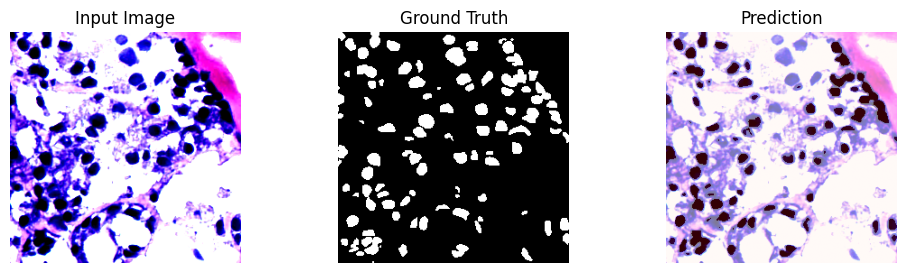

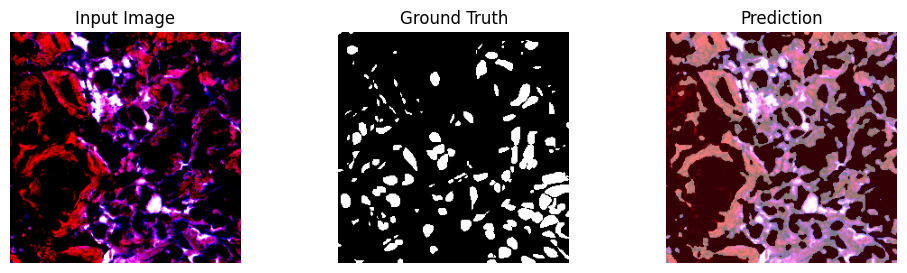

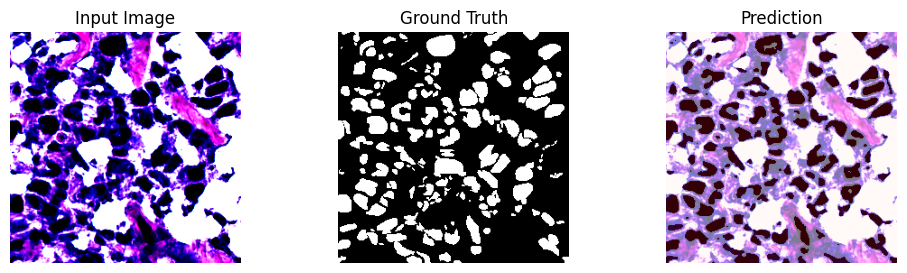

In [ ]:
import matplotlib.pyplot as plt

model.eval()
imgs, masks = next(iter(val_loader))
imgs, masks = imgs.to(device), masks.to(device)
with torch.no_grad():
    preds = model(imgs)

# Plot first 3 results
for i in range(3):
    img_np = imgs[i].permute(1,2,0).cpu().numpy()
    true_np = masks[i][0].cpu().numpy()
    pred_np = (preds[i][0] > 0.5).float().cpu().numpy()

    plt.figure(figsize=(12, 3))
    plt.subplot(1, 3, 1); plt.imshow(img_np); plt.title("Input Image"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(true_np, cmap='gray'); plt.title("Ground Truth"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(img_np); plt.imshow(pred_np, cmap='Reds', alpha=0.5); plt.title("Prediction"); plt.axis("off")
    plt.show()


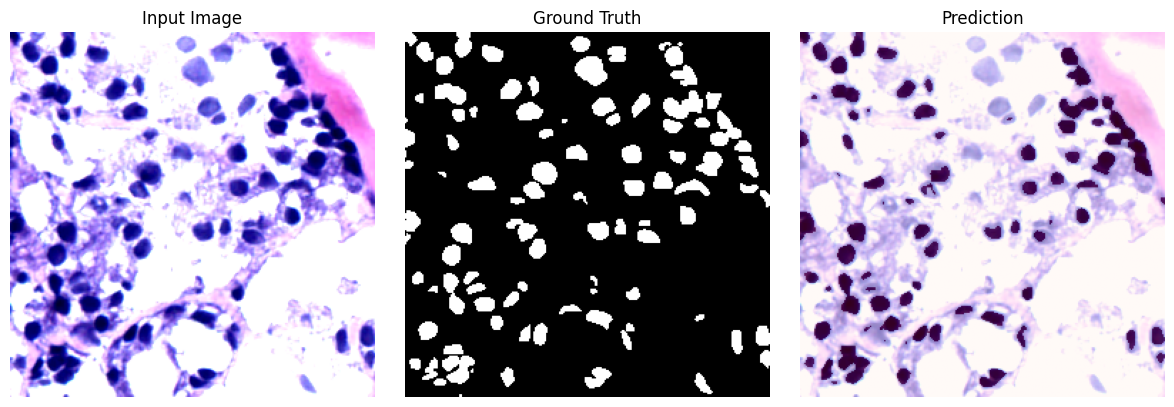

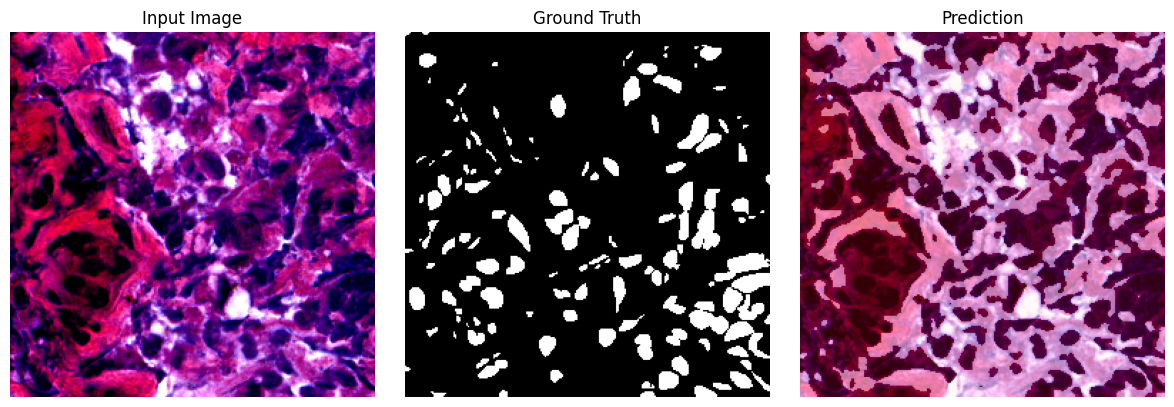

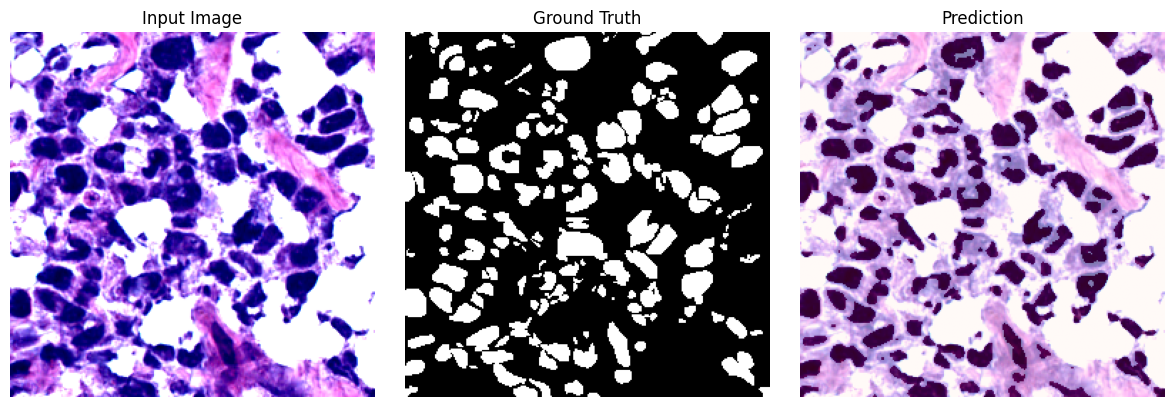

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

model.eval()
images_shown = 3  # Number of samples to visualize

with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        preds = model(imgs)
        preds = (preds > 0.5).float()

        for i in range(images_shown):
            # ---- Unnormalize input image for display ----
            img_np = imgs[i].cpu().permute(1, 2, 0).numpy()
            img_np = img_np * 0.5 + 0.5  # If Normalize(mean=0.5, std=0.5) used
            img_np = np.clip(img_np, 0, 1)

            # ---- Ground truth and predicted masks ----
            mask_np = masks[i].squeeze().cpu().numpy()
            pred_np = preds[i].squeeze().cpu().numpy()

            # ---- Plot ----
            fig, axs = plt.subplots(1, 3, figsize=(12, 4))
            axs[0].imshow(img_np)
            axs[0].set_title("Input Image")
            axs[1].imshow(mask_np, cmap='gray')
            axs[1].set_title("Ground Truth")
            axs[2].imshow(img_np)
            axs[2].imshow(pred_np, alpha=0.5, cmap='Reds')
            axs[2].set_title("Prediction")
            for ax in axs:
                ax.axis('off')
            plt.tight_layout()
            plt.show()

        break  # Only show first batch


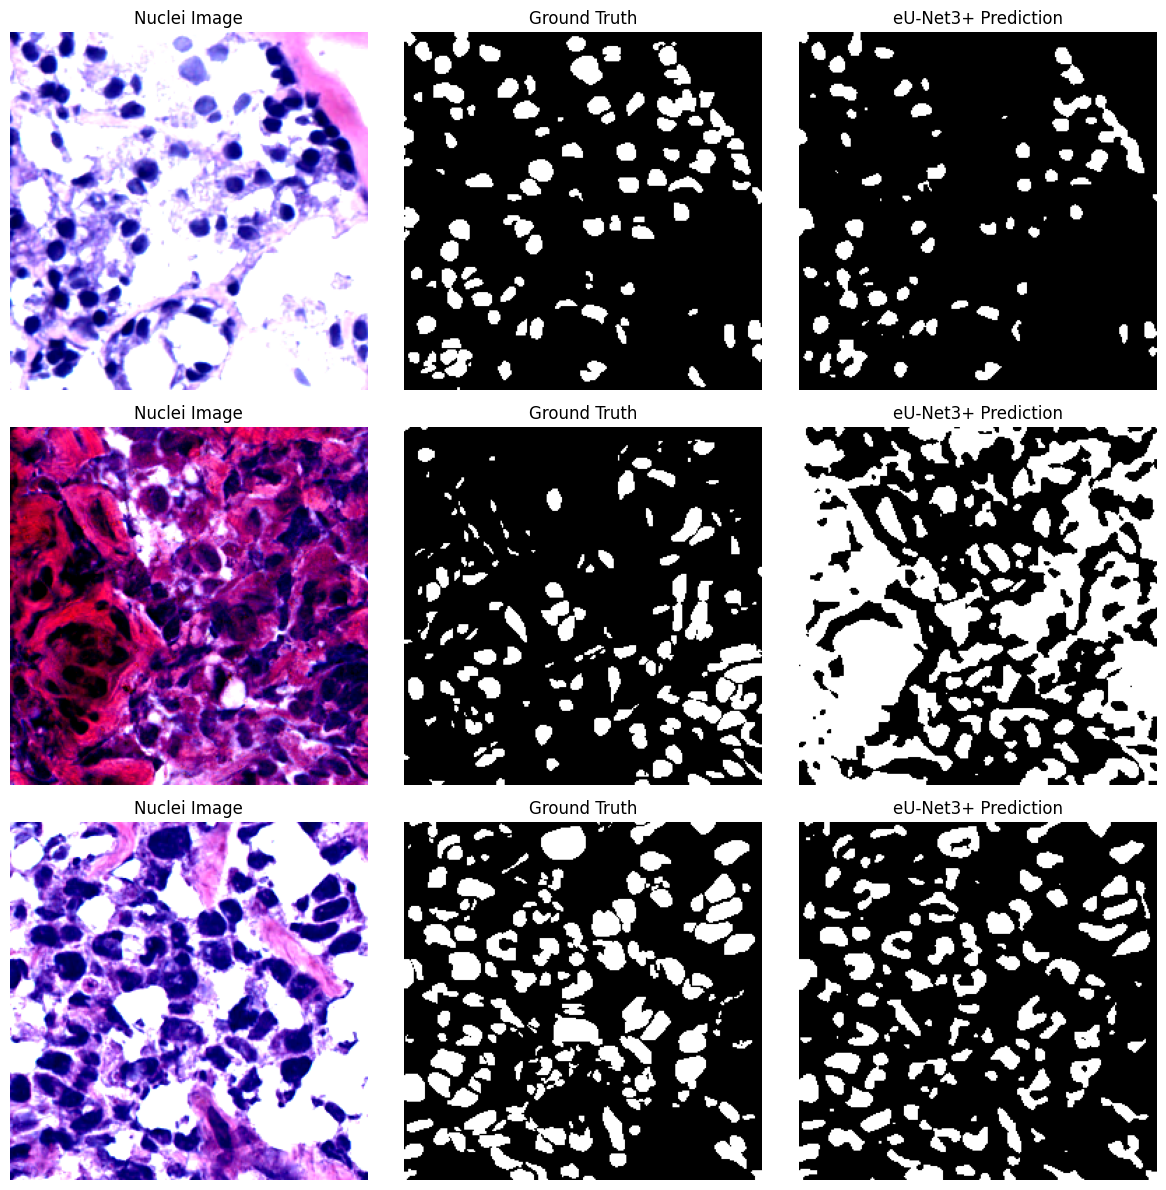

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

model.eval()
samples_to_show = 3  # rows

with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        preds = model(imgs)
        preds = (preds > 0.5).float()

        fig, axs = plt.subplots(samples_to_show, 3, figsize=(12, 4 * samples_to_show))

        for i in range(samples_to_show):
            # ---- Unnormalize ----
            img_np = imgs[i].cpu().permute(1, 2, 0).numpy()
            img_np = img_np * 0.5 + 0.5
            img_np = np.clip(img_np, 0, 1)

            mask_np = masks[i].squeeze().cpu().numpy()
            pred_np = preds[i].squeeze().cpu().numpy()

            # ---- Row i ----
            axs[i, 0].imshow(img_np)
            axs[i, 0].set_title("Nuclei Image")
            axs[i, 1].imshow(mask_np, cmap='gray')
            axs[i, 1].set_title("Ground Truth")
            axs[i, 2].imshow(pred_np, cmap='gray')
            axs[i, 2].set_title("eU-Net3+ Prediction")

            for j in range(3):
                axs[i, j].axis('off')

        plt.tight_layout()
        plt.show()
        break


Corrected output code


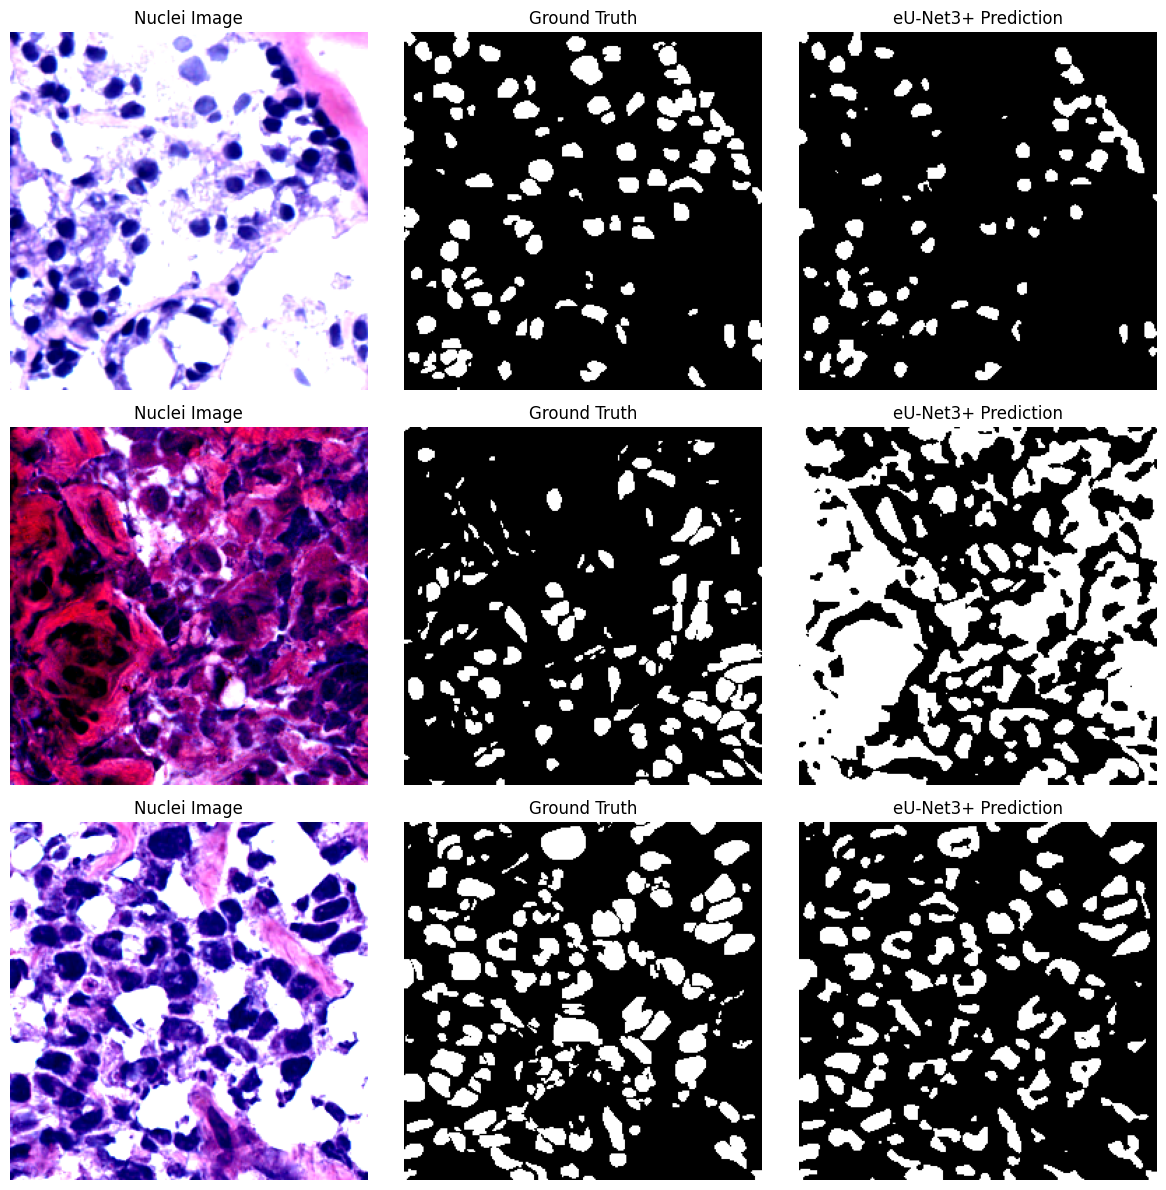

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

model.eval()
samples_to_show = 3  # Number of rows (samples)

with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        preds = model(imgs)
        preds = (preds > 0.5).float()  # Binarize predictions

        fig, axs = plt.subplots(samples_to_show, 3, figsize=(12, 4 * samples_to_show))

        for i in range(samples_to_show):
            # === Unnormalize image ===
            img_np = imgs[i].cpu().permute(1, 2, 0).numpy()
            img_np = img_np * 0.5 + 0.5  # assuming mean=0.5, std=0.5
            img_np = np.clip(img_np, 0, 1)

            mask_np = masks[i].squeeze().cpu().numpy()
            pred_np = preds[i].squeeze().cpu().numpy()

            # === Plot each column ===
            axs[i, 0].imshow(img_np)
            axs[i, 0].set_title("Nuclei Image")

            axs[i, 1].imshow(mask_np, cmap='gray', vmin=0, vmax=1)
            axs[i, 1].set_title("Ground Truth")

            axs[i, 2].imshow(pred_np, cmap='gray', vmin=0, vmax=1)
            axs[i, 2].set_title("eU-Net3+ Prediction")

            for j in range(3):
                axs[i, j].axis('off')

        plt.tight_layout()
        plt.show()
        break  # Only show first batch


In [ ]:
# Save trained model weights
torch.save(model.state_dict(), "eunet3p_cryo.pth")
print("✅ Model saved as eunet3p_cryo.pth")


✅ Model saved as eunet3p_cryo.pth


In [ ]:
from google.colab import files
files.download("eunet3p_cryo.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Step 1: Re-create the model
model = EUnet3Plus().to(device)

# Step 2: Load the saved weights
model.load_state_dict(torch.load("eunet3p_cryo.pth", map_location=device))
model.eval()

print("✅ Model loaded and ready for inference")
